In [1]:
import pandas as pd
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import os

### Analysis dependant global variables

In [29]:
# pep_folder = "NLFR_analysis"
# wt_seq = "NLFRRVWEL"
# pep_short = "NLFR"
# pep_file = "TCRneo_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-B*08:01"
# exp_prefix = "TCRneo"


pep_folder = "EVDP_analysis"
wt_seq = "EVDPIGHLY"
pep_short = "EVDP"
pep_file = "TCRA3_duplex_fingerprint_data_WT_TCR.tsv"
HLA_allele = "HLA-A*01:01"
exp_prefix = "TCRA3"

# pep_folder = "SLLQ_analysis"
# wt_seq = "SLLQHLIGL"
# pep_short = "SLLQ"
# pep_file = "PRAMEb_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-A*02:01"
# exp_prefix = "PRAMEb"


fig_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/figures/{pep_folder}/"

### Importing data

In [82]:
matrix_exp = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_exp_duplex.tsv", sep="\t", index_col=0)
matrix_pmhc_score = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_score_netmhcpan.tsv", sep="\t", index_col=0)
matrix_bl = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_bl_raw.tsv", sep="\t", index_col=0)
matrix_bl_cond = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_bl_cond.tsv", sep="\t", index_col=0)
matrix_bl_scaled= pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_bl_rescaled.tsv", sep="\t", index_col=0)
matrix_af = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_af_interface.tsv", sep="\t", index_col=0)
matrix_esm = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_ESM_IF.tsv", sep="\t", index_col=0)
matrix_esm.columns = matrix_esm.columns.astype(float).astype(int)

# List of peptides to test 

df_pep = pd.read_csv("/home/projects2/morni2/randompeps/randompeps_9mer_1000000.pep", header=None, comment="#", names=["peptide"])

cleaned_df_pep = df_pep.dropna(subset=["peptide"]).reset_index(drop=True)
df_all = cleaned_df_pep.copy()

In [25]:
print(matrix_pmhc_score.head())


                    1         2         3         4         5         6  \
Peptide_res                                                               
A            0.836159  0.933952  0.871774  0.860284  0.235766  0.853210   
C            0.293286  0.462429  0.370563  0.392694  0.023704  0.514039   
D            0.924600  0.327703  0.740425  0.879075  0.227994  0.720380   
E            0.925507  0.432641  0.712618  0.911683  0.313878  0.775178   
F            0.902191  0.708100  0.912515  0.742672  0.240422  0.908179   

                    7         8         9  
Peptide_res                                
A            0.950100  0.939955  0.393492  
C            0.822524  0.666476  0.174659  
D            0.883406  0.718411  0.006025  
E            0.931905  0.912515  0.052532  
F            0.920557  0.654550  0.732446  


### Functions (visualization for heatmap, and correlation)

In [77]:
def plot_heatmap(matrix, labels, title, scale_center, fig_name = "", save_fig = False):

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sns.heatmap(
        matrix,
        cmap="RdBu",
        center=scale_center,
        cbar_kws={"label": labels},
        ax=ax,
    )

    # Highlighting the WT sequence 
    for pos, aa in enumerate(wt_seq, start=1):
        if aa in matrix.index :
            y = matrix.index.get_loc(aa)
            ax.add_patch(
                patches.Rectangle(
                    (pos-1, y), 1, 1, fill=False, edgecolor="black", lw=2
                )
            )

    # Crossing out the residues without data
    for r_idx, aa in enumerate(matrix.index):
        for c_idx, pos in enumerate(matrix.columns):
            if pd.isna(matrix.loc[aa, pos]):
                ax.text(
                    c_idx + 0.5,
                    r_idx + 0.5,
                    "X",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=11,
                )

    ax.set_title(f"{title} - {HLA_allele} + {wt_seq}")
    ax.set_xlabel("Peptide_pos")
    ax.set_ylabel("Peptide_res")
    plt.tight_layout()

    if save_fig == True:
        plt.savefig(
          os.path.join(fig_folder, fig_name), dpi=300
      )
        
    plt.show()

def compute_columnwise_pcc(df_ref, df_pred):
    df_ref = df_ref.copy()
    df_pred = df_pred.copy()
    df_ref.columns = [int(c) for c in df_ref.columns]
    df_pred.columns = [int(c) for c in df_pred.columns]

    records = []
    common_cols = [col for col in df_ref.columns if col in df_pred.columns]

    for pos in common_cols:
        combined = pd.concat([df_ref[pos].rename("ref"), df_pred[pos].rename("pred")], axis=1).dropna()
        
        x = combined["ref"].astype(float)
        y = combined["pred"].astype(float)

        # Pearson requires at least 3 points and non-zero standard deviation
        if len(x) >= 3 and x.std() > 1e-8 and y.std() > 1e-8:
            p_res = stats.pearsonr(x, y)
            s_res = stats.spearmanr(x, y)
            pcc, pcc_pval = p_res.statistic, p_res.pvalue
            scc, scc_pval = s_res.statistic, s_res.pvalue
        else:
            pcc, pcc_pval, scc, scc_pval = np.nan, np.nan, np.nan, np.nan

        records.append({
            "Peptide_pos": pos,
            "PCC": pcc,
            "p_value_pcc": pcc_pval,
            "SCC": scc,
            "p_value_scc": scc_pval,
            "n_points": len(x)
        })

    return pd.DataFrame(records)


def plot_bars(ax, df, metric_name, pval_col, title):
    bars = ax.bar(
        df["Peptide_pos"],
        df[metric_name],
        color="#4C72B0",
        edgecolor="black",
        width=0.6,
        alpha=0.85
    )

    # Add significance stars
    for idx, row in df.iterrows():
        val = row[metric_name]
        pval = row[pval_col]
        if not np.isnan(val):
            star = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else ""))
            y_pos = val + (0.02 if val >= 0 else -0.06)
            ax.text(
                row["Peptide_pos"],
                y_pos,
                star,
                ha="center",
                va="bottom" if val >= 0 else "top",
                fontsize=11,
                fontweight="bold"
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_ylim(-1.05, 1.15)
    ax.set_xticks(range(1, 10))
    ax.set_xlabel("Peptide position")
    ax.set_title(title, fontsize=12)





## Functions for scoring 

In [88]:
def score_full_peptides(input_df, scoring_matrix, pep_col,  score_prefix, aggregation="sum"):
    """
    The input must be a dataframe with at least a column containing the peptides being tested. 
    It is then returned with 2 additionnal columns containing the scored peptides and their rank.
    """

    df = input_df.copy()
    
    sc_mat = scoring_matrix.copy()
    sc_mat.columns = sc_mat.columns.astype(int)

    scores = []
    
    for pep in df[pep_col]:
        if len(pep) != 9:
            scores.append(np.nan)
            continue
            
        pred_pos_scores = []
        
        for pos, aa in enumerate(pep, start=1):
            if aa in sc_mat.index and pos in sc_mat.columns:
                pred_pos_scores.append(sc_mat.loc[aa, pos])
            else:
                pred_pos_scores.append(np.nan)
                
        if aggregation == "sum":
            final_score = np.sum(pred_pos_scores) if not any(np.isnan(pred_pos_scores)) else np.nan
        elif aggregation == "prod":
            final_score = np.prod(pred_pos_scores) if not any(np.isnan(pred_pos_scores)) else np.nan
            
        scores.append(final_score)
        
    df[f"{score_prefix}_score"] = scores
    df[f"{score_prefix}_rank"] = df[f"{score_prefix}_score"].rank(ascending=False, method="min")
        
    return df

# def score_cross_metrics(df_input, exp_prefix, score_prefix, return_dict=False):
#     """
#     Compute correlation scores and look for matching hits between an experimental 
#     and predictive score (or 2 scores, the first being the reference one)
#     """

#     clean_df = df_input.dropna(subset=[f"{score_prefix}_score", f"{exp_prefix}_score"])
    

#     scc, pval = stats.spearmanr(clean_df[f"{score_prefix}_score"], clean_df[f"{exp_prefix}_score"])
#     pcc, pval2 = stats.pearsonr(clean_df[f"{score_prefix}_score"], clean_df[f"{exp_prefix}_score"])


#     top_k_exp = set(clean_df.nlargest(100, f"{exp_prefix}_score")["peptide"])
#     top_k_pred = set(clean_df.nlargest(100, f"{score_prefix}_score")["peptide"])

#     overlap_100 = len(top_k_exp.intersection(top_k_pred))

#     # Checking the predicted Top 1000 (first 0.1 %)
#     top_1000_pred = set(clean_df.nlargest(1000, f"{score_prefix}_score")["peptide"])
#     overlap_in_top1000 = len(top_k_exp.intersection(top_1000_pred))

#     print(f"[{score_prefix} vs {exp_prefix}]")
#     print(f"  SCC: {scc:.4f} (p-val: {pval:.2e})")
#     print(f"  PCC: {pcc:.4f} (p-val: {pval2:.2e})")
#     print(f"  Overlap in top 100: {overlap_100}/100 peptides")
#     print(f"  Top 100 captured in predicted top 1000: {overlap_in_top1000}/100 peptides\n")


#     if return_dict:
#         return {
#             "model": score_prefix,
#             "exp_ref": exp_prefix,
#             "scc": scc,
#             "pcc": pcc,
#             "top100_overlap": overlap_100,
#             "top100_in_top1000": overlap_in_top1000
#         }

# version with percentiles instead of absolute numbers of top hits

def score_cross_metrics(df_input, exp_prefix, score_prefix, return_dict=True, percentiles=[0.1, 1]):
    """
    Compute correlation scores and look for matching hits between an experimental 
    and predictive score (or 2 scores, the first being the reference one)
    """

    clean_df = df_input.dropna(subset=[f"{score_prefix}_score", f"{exp_prefix}_score"])
    n_tot = len(clean_df)
    

    scc, pval = stats.spearmanr(clean_df[f"{score_prefix}_score"], clean_df[f"{exp_prefix}_score"])
    pcc, pval2 = stats.pearsonr(clean_df[f"{score_prefix}_score"], clean_df[f"{exp_prefix}_score"])

    n_ref = max(1, int(n_tot * 0.001))
    top_ref_exp = set(clean_df.nlargest(n_ref, f"{exp_prefix}_score")["peptide"])

    res = {
        "model": score_prefix,
        "scc": round(float(scc), 4),
        "pcc": round(float(pcc), 4),
        "N_ref_0.1%": n_ref
    }
    
    print(f"[{score_prefix} vs {exp_prefix}]")
    print(f"  SCC: {scc:.4f} (p-val: {pval:.2e})")
    print(f"  PCC: {pcc:.4f} (p-val: {pval2:.2e})")

    for p in percentiles:
        k_pred = max(1, int(n_tot * (p / 100.0)))
        top_k_pred = set(clean_df.nlargest(k_pred, f"{score_prefix}_score")["peptide"])
        overlap = len(top_ref_exp.intersection(top_k_pred))
        recall = overlap / n_ref * 100.0
        res[f"recall_top{p}%"] = round(recall, 2)
        res[f"overlap_top{p}%"] = overlap
        print(f"Top 0.1% captured in predicted top {p}%: {recall:.1f}% ({overlap}/{n_ref} peptides)")

    if return_dict:
        return res

## First analysis: Rescaled matrices (range [0,1])

### Hybrid Score Design: pMHC $\times$ BLOSUM62

To rank mutant peptide candidates against experimental binding data, we combine NetMHCpan presentation predictions with BLOSUM62 sequence conservation using the following naive formulation:

$$S_{i, j} = \text{pMHC}_{i, j} \times \left(1 + \text{BL}_{\text{scaled}, i, j}\right)$$

$$S_{i, j} = \text{BL}_{i, j} \times \left(1 - \text{pMHC}_{i, j}\right) + \text{pMHC}_{i, j}$$

#### Key Rationales:
* **MHC Presentation as a Mandatory Gate ($\text{pMHC} \to 0$):**  
  Peptide presentation by the MHC is an absolute biological prerequisite. If a mutation destroys binding at anchor positions (P2, P9), $\text{pMHC} \to 0$, forcing $S \to 0$ regardless of favorable physicochemical properties elsewhere.
* **Positive Modulation on Permissive Positions ($\text{pMHC} \approx 1$):**  
  On non-anchor positions where MHC binding is widely tolerated, $\text{pMHC}$ acts as a neutral baseline ($1.0$), allowing the $(1 + \text{BL}_{\text{scaled}})$ factor to discriminate mutants based on sequence conservation and TCR compatibility.
* **Column-wise Min-Max Scaling ($\text{BL}_{\text{scaled}} \in [0, 1]$):**  
  Standard global scaling on BLOSUM62 introduces an artifact: Tryptophan's extreme self-identity score ($+11$) artificially suppresses non-W positions below $0.5$. Scaling each column independently relative to its position's WT residue ensures that:
  1. Every wild-type residue anchors at exactly $1.0$.
  2. Scores remain strictly positive ($[1.0, 2.0]$ multiplier), preventing rank inversions caused by negative raw BLOSUM values.

In [ ]:
scoring_mat = matrix_pmhc_score * (1 + matrix_bl_scaled)
# print(matrix_pmhc_score.head())
# print(matrix_bl_scaled.head())
print(scoring_mat.head())

In [ ]:
df_all = score_full_peptides(df_all, matrix_exp, pep_col="peptide",score_prefix="exp", aggregation="sum")
# df_all = score_full_peptides(df_all, scoring_mat, pep_col="peptide", score_prefix="pred", aggregation="sum")

# top_hits_pred = df_all.sort_values(by="pred_score", ascending=False)
# print(top_hits_pred.head(10))

# top_hits_exp = df_all.sort_values(by="exp_score", ascending=False)
# print(top_hits_exp.head(10))

Now trying with the netMHCpan score alone to see if the BLOSUM addition was worth it!

In [ ]:
df_all = score_full_peptides(df_all, matrix_pmhc_score, pep_col="peptide", score_prefix="pMHC", aggregation="sum")

Conversely, trying to score with only the BLOSUM matrix

In [ ]:
df_all = score_full_peptides(df_all, matrix_bl_scaled, pep_col="peptide", score_prefix="BL", aggregation="sum")

And with a 2nd version of the naive score, where we just multiply blosum and netMHCpan scores:

In [ ]:
scoring_mat2 = matrix_pmhc_score * matrix_bl_scaled
df_all = score_full_peptides(df_all, scoring_mat2, pep_col="peptide", score_prefix="part_woAF3", aggregation="sum")

### Updated score design with AF interface score

$$S_{i, j} = \text{pMHC}_{i, j} \times \text{BL}_{\text{scaled}, i, j} \times \text{AF3}_{i, j}$$

In [ ]:
full_scoring_mat = matrix_pmhc_score * matrix_bl_scaled * matrix_af
df_all = score_full_peptides(df_all, full_scoring_mat, pep_col="peptide", score_prefix="full", aggregation="sum")

(Small check to see if it correlates with exp data)

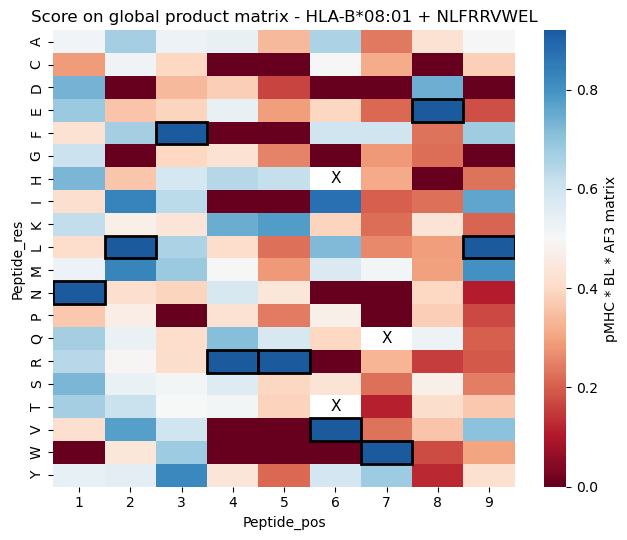

In [109]:
full_scoring_mat = matrix_pmhc_score * matrix_bl_scaled * matrix_af
mat_geom = (matrix_pmhc_score * matrix_bl_scaled * matrix_af) ** (1 / 3)
plot_heatmap(mat_geom, "pMHC * BL * AF3 matrix", "Score on global product matrix", 0.5)# , "heatmap_glob_score", save_fig = Tru

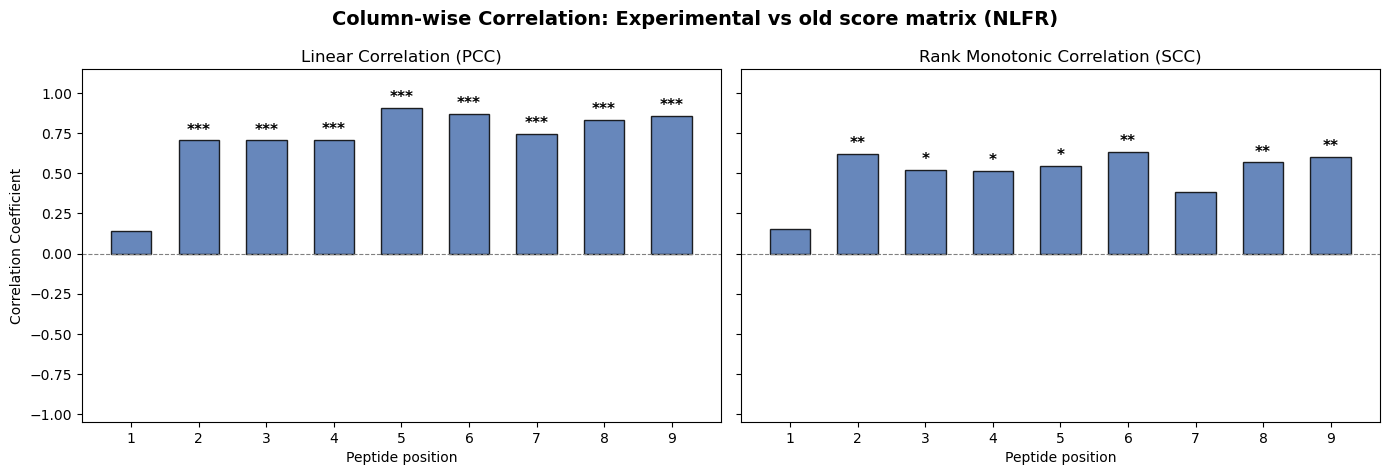

In [103]:
pcc_old_score_exp = compute_columnwise_pcc(matrix_exp, full_scoring_mat)

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_old_score_exp,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_old_score_exp.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")


plot_bars(
    ax2,
    pcc_old_score_exp,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_old_score_exp.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig1.suptitle(f"Column-wise Correlation: Experimental vs old score matrix ({pep_short})", fontsize=14, fontweight="bold", y=0.98)

plt.tight_layout()
plt.savefig(os.path.join(fig_folder, "pcc_exp_full_score"), dpi=300)
plt.show()

First, trying to score with the AF output only

In [ ]:
df_all = score_full_peptides(df_all, matrix_af, pep_col="peptide", score_prefix="AF3", aggregation="sum")

Alternative score without BLOSUM to see how this impacts the global results

In [ ]:
partial_scoring_mat_woBL = matrix_pmhc_score * matrix_af
df_all = score_full_peptides(df_all, partial_scoring_mat_woBL, pep_col="peptide", score_prefix="part_woBL", aggregation="sum")

Alternative score without pMHC score to see how this impacts the global results

In [ ]:
partial_scoring_mat_woMHC = matrix_bl_scaled * matrix_af
df_all = score_full_peptides(df_all, partial_scoring_mat_woMHC, pep_col="peptide", score_prefix="part_woMHC", aggregation="sum")

### Adding Inverse Folding analysis

In [39]:
df_all = score_full_peptides(df_all, matrix_esm, pep_col="peptide", score_prefix="IF", aggregation="sum")

### Computing metrics for all scores

Running all benchmark metrics at once and summarizing results in a df

In [22]:
benchmark = [
    score_cross_metrics(df_all, "exp", model) 
    for model in ["pMHC", "BL", "AF3", "IF", "part_woAF3", "part_woMHC", "part_woBL", "full"]
]
df_summary = pd.DataFrame(benchmark).set_index("model")

[pMHC vs exp]
  SCC: 0.5729 (p-val: 0.00e+00)
  PCC: 0.5846 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 4.6% (41/889 peptides)
Top 0.1% captured in predicted top 1%: 38.0% (338/889 peptides)
[BL vs exp]
  SCC: 0.6775 (p-val: 0.00e+00)
  PCC: 0.6971 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 25.0% (222/889 peptides)
Top 0.1% captured in predicted top 1%: 67.3% (598/889 peptides)
[AF3 vs exp]
  SCC: 0.3818 (p-val: 0.00e+00)
  PCC: 0.4072 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 6.6% (59/889 peptides)
Top 0.1% captured in predicted top 1%: 27.9% (248/889 peptides)
[IF vs exp]
  SCC: 0.2919 (p-val: 0.00e+00)
  PCC: 0.3035 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 2.8% (25/889 peptides)
Top 0.1% captured in predicted top 1%: 13.0% (116/889 peptides)


KeyError: ['part_woAF3_score']

Adding a score to an already existing summary dataframe

In [40]:
row_if = score_cross_metrics(df_all, "exp", "IF")
df_if = pd.DataFrame([row_if]).set_index("model")
df_summary = pd.concat([df_summary, df_if])

[IF vs exp]
  SCC: 0.1920 (p-val: 0.00e+00)
  PCC: 0.1982 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 1.6% (16/1000 peptides)
Top 0.1% captured in predicted top 1%: 9.5% (95/1000 peptides)


### Export data

In [42]:
# df_all.to_csv(f"../results/{pep_folder}/peptides_scored_summary.csv", index=False)
# df_summary.to_csv(f"../results/{pep_folder}/peptides_scored_metrics_perc.csv", index="model")

In [27]:
df_summary 

,scc,pcc,N_ref_0.1%,recall_top0.1%,overlap_top0.1%,recall_top1%,overlap_top1%
model,,,,,,,
pMHC,0.1580,0.1594,1000,0.1,1,3.5,35
BL,0.3481,0.3630,1000,4.4,44,19.8,198
AF3,0.1372,0.1374,1000,0.0,0,1.8,18
part_woAF3,0.3221,0.3356,1000,3.5,35,17.1,171
part_woMHC,0.3692,0.3839,1000,4.3,43,20.9,209
part_woBL,0.1808,0.1829,1000,0.4,4,4.4,44
full,0.3422,0.3555,1000,3.7,37,18.3,183


We can also import the latest results dataframe to work with it without having to compute again all scores

In [30]:
df_all = pd.read_csv(f"../results/{pep_folder}/peptides_scored_summary.csv")
df_summary = pd.read_csv(f"../results/{pep_folder}/peptides_scored_metrics_perc.csv", index_col="model")

In [12]:
df_all.head()

,peptide,exp_score,exp_rank,pMHC_score,pMHC_rank,BL_score,BL_rank,part_woAF3_score,part_woAF3_rank,full_score,full_rank,AF3_score,AF3_rank,part_woBL_score,part_woBL_rank,part_woMHC_score,part_woMHC_rank
0,SREMRRADS,-7.450683,149964.0,5.140135,958999.0,3.197727,358624.0,2.144765,534851.0,1.357953,515986.0,5.417725,606920.0,3.197640,916625.0,1.966100,377832.0
1,VLNGYEIGG,-4.316199,61125.0,7.145540,103952.0,3.972403,109300.0,3.611757,58364.0,2.416898,39722.0,6.018194,23343.0,4.868517,19735.0,2.658270,72358.0
2,FTESEDYQA,-22.143608,896630.0,7.081143,123959.0,2.240584,797721.0,1.735568,734090.0,1.014123,770830.0,5.688819,243110.0,4.425335,126578.0,1.339549,813968.0
3,NEEQDKRFV,-7.138223,138630.0,6.258718,495079.0,3.103247,399381.0,2.545840,346596.0,1.482478,423708.0,4.855510,978736.0,3.327553,866922.0,1.803688,491937.0
4,LAEEANKPG,-21.363154,873230.0,5.279812,935422.0,1.808766,927719.0,1.214665,920348.0,0.537405,978728.0,4.782561,987082.0,2.706736,992233.0,0.888510,977080.0


Exporting top 0.1% hits of few scores to compare to experimental data trough logos

In [31]:
n_ref = int(len(df_all.dropna()) * 0.001)

# Exporting top hits for these models
models_to_plot = ["AF3"]

for m in models_to_plot:
    col = f"{m}_score"
    top_peptides = df_all.nlargest(n_ref, col)["peptide"]

    # ensure that the scoring folder is created
    os.makedirs(f"../data/{pep_folder}/scoring/", exist_ok = True)
    # Just exporting with one peptide a line
    out_file = f"../data/{pep_folder}/scoring/logo_top0.1pct_{m}.txt"
    top_peptides.to_csv(out_file, index=False, header=False)

## New way of scoring: using log-space

### Rescaling matrices: 25% Lower Bound log ratio

For some matrices, value ranges from 0 to 1: no penalization for mutations destabilizing. As experimental data is expressed in log2 mean UMI counts, we use the same approach by taking the log of the ratio between the values, and the 25% Lower Bound value, so as the top 25% worse mutations will have a score < 0

In [83]:
# Just to observe the predicted scales for nem matrices
for name, mat in [("BL_scaled", matrix_bl_scaled), ("BL_raw", matrix_bl), ("pMHC", matrix_pmhc_score), ("ipSAE", matrix_af)]:
  
  lb = np.nanpercentile(mat.values, 25)
  lb = max(lb, 0.05)
  mat_log = np.log2((mat.values + 0.01) / lb)
  print(
      f"{name:6s} | LB25: {lb:.3f} | Min (s=0): {np.nanmin(mat_log):.2f} | Max"
      f" (s=1): {np.nanmax(mat_log):.2f}"
  )

BL_scaled | LB25: 0.111 | Min (s=0): -3.47 | Max (s=1): 3.18
BL_raw | LB25: 0.050 | Min (s=0): -2.32 | Max (s=1): 7.78
pMHC   | LB25: 0.581 | Min (s=0): -5.18 | Max (s=1): 0.77
ipSAE  | LB25: 0.408 | Min (s=0): -5.35 | Max (s=1): 1.10


/tmp/ipykernel_1469622/2998993753.py:6: RuntimeWarning: invalid value encountered in log2
  mat_log = np.log2((mat.values + 0.01) / lb)


In [ ]:
lb = np.nanpercentile(matrix_pmhc_score.values, 25)
lb = max(lb, 0.05) # avoid division by 0, while still allowing some negative values if lb = 0
matrix_pmhc_log = np.log2((matrix_pmhc_score + 0.01) / lb) # adding a small epsilon to avoid log(0). If LB = 0, we still have min = -2.3

lb = np.nanpercentile(matrix_bl_scaled, 25)
lb = max(lb, 0.05) 
matrix_bl_log = np.log2((matrix_bl_scaled + 0.01) / lb) 

lb = np.nanpercentile(matrix_af, 25)
lb = max(lb, 0.05) 
matrix_af_log = np.log2((matrix_af + 0.01) / lb) 


### Quick visualization of new heatmaps

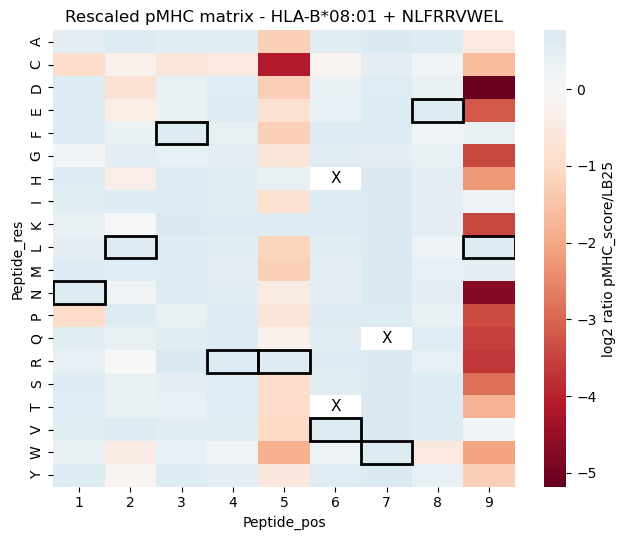

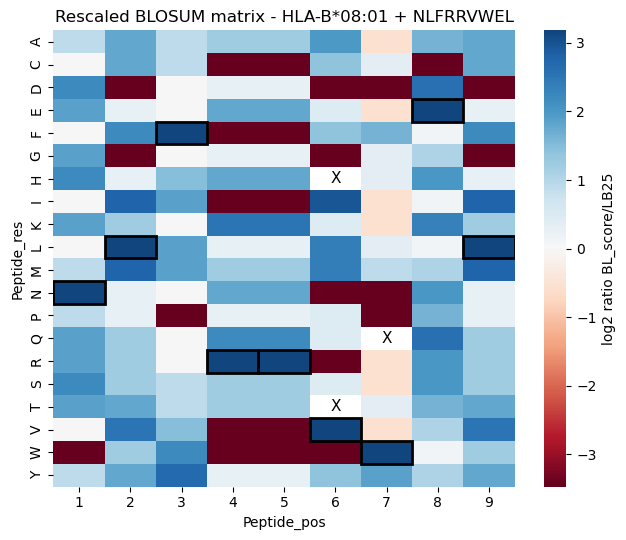

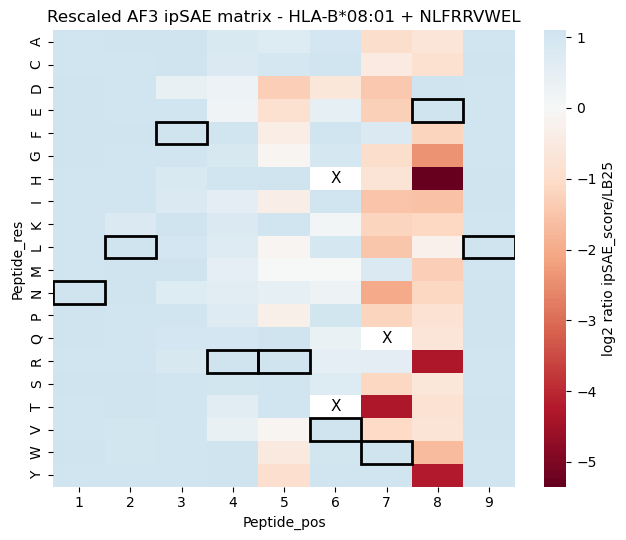

In [78]:
plot_heatmap(matrix_pmhc_log, "log2 ratio pMHC_score/LB25", "Rescaled pMHC matrix", 0.0, "heatmap_log_pMHC", save_fig = True)
plot_heatmap(matrix_bl_log, "log2 ratio BL_score/LB25", "Rescaled BLOSUM matrix", 0.0, "heatmap_log_BL", save_fig = True)
plot_heatmap(matrix_af_log, "log2 ratio ipSAE_score/LB25", "Rescaled AF3 ipSAE matrix", 0.0, "heatmap_log_ipSAE", save_fig = True)

### Creating full score matrice, correlation with experimental data? 

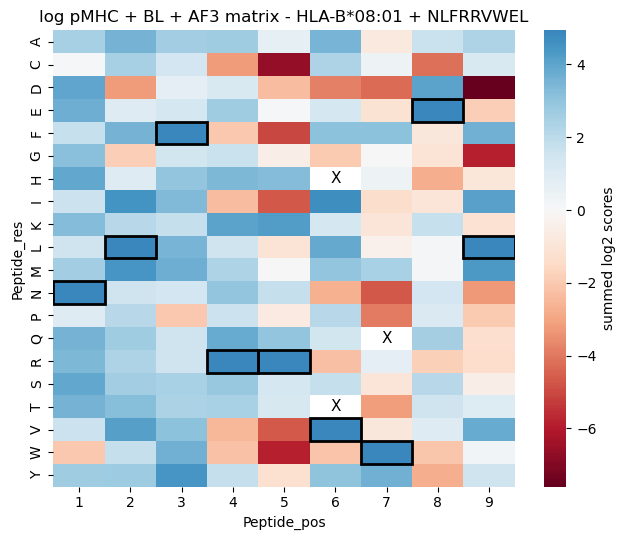

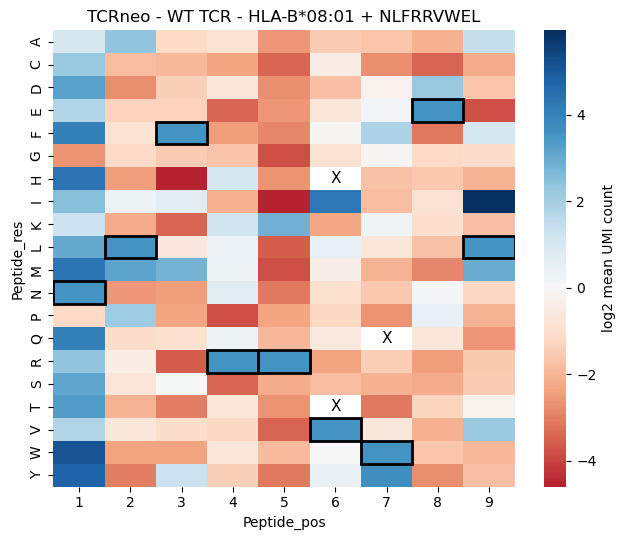

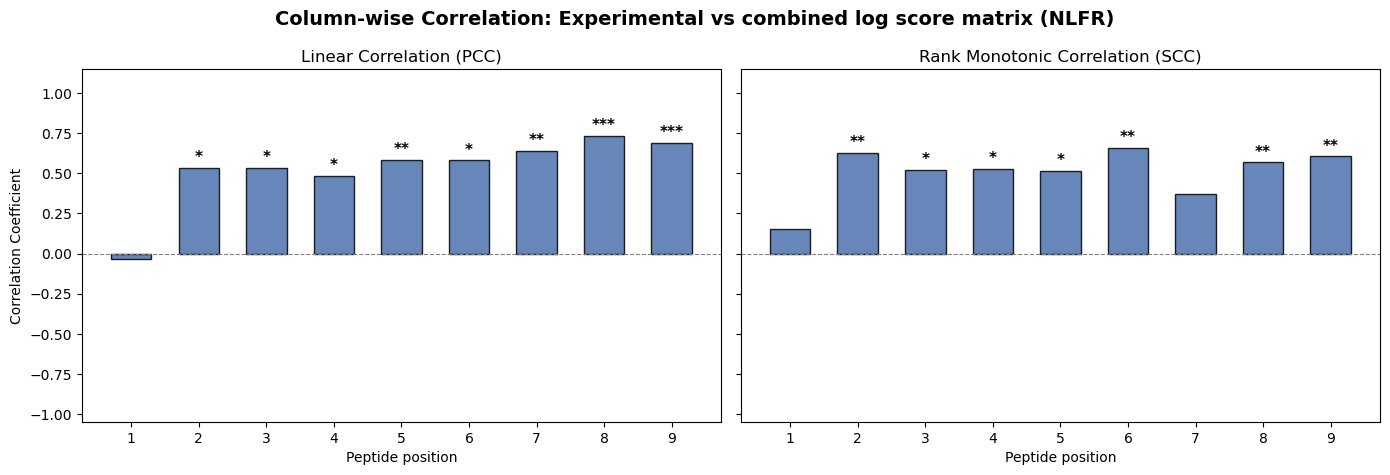

In [102]:
matrix_full_log = matrix_pmhc_log + matrix_bl_log + matrix_af_log

plot_heatmap(matrix_full_log, "summed log2 scores", "log pMHC + BL + AF3 matrix", 0.0, "heatmap_log_score", save_fig = True)
plot_heatmap(matrix_exp, "log2 mean UMI count", f"{exp_prefix} - WT TCR", 0.0) # as a reminder to compare
pcc_log_score_exp = compute_columnwise_pcc(matrix_exp, matrix_full_log)

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_log_score_exp,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_log_score_exp.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")


plot_bars(
    ax2,
    pcc_log_score_exp,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_log_score_exp.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig1.suptitle(f"Column-wise Correlation: Experimental vs combined log score matrix ({pep_short})", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(fig_folder, "pcc_exp_log_score"), dpi=300)
plt.show()

### Create new scoring summary based on these metrics

In [92]:
df_log_all = cleaned_df_pep.copy()

for (metric_matrix, name) in [
        (matrix_exp, "exp"),
        (matrix_pmhc_log, "pMHC_log"), 
        (matrix_bl_log, "BL_log"), 
        (matrix_af_log, "AF3_log"),
        (matrix_full_log, "full_log")
        ]:
    df_log_all = score_full_peptides(df_log_all, metric_matrix, pep_col="peptide",score_prefix=name, aggregation="sum")

benchmark_log = [
    score_cross_metrics(df_log_all, "exp", model) 
    for model in ["pMHC_log", "BL_log", "AF3_log", "full_log"]
]
df_log_summary = pd.DataFrame(benchmark_log).set_index("model")

[pMHC_log vs exp]
  SCC: 0.4976 (p-val: 0.00e+00)
  PCC: 0.5044 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 4.6% (41/889 peptides)
Top 0.1% captured in predicted top 1%: 38.7% (344/889 peptides)
[BL_log vs exp]
  SCC: 0.4627 (p-val: 0.00e+00)
  PCC: 0.4766 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 18.0% (160/889 peptides)
Top 0.1% captured in predicted top 1%: 49.6% (441/889 peptides)
[AF3_log vs exp]
  SCC: 0.3087 (p-val: 0.00e+00)
  PCC: 0.3187 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 6.6% (59/889 peptides)
Top 0.1% captured in predicted top 1%: 18.7% (166/889 peptides)
[full_log vs exp]
  SCC: 0.5824 (p-val: 0.00e+00)
  PCC: 0.5957 (p-val: 0.00e+00)
Top 0.1% captured in predicted top 0.1%: 24.3% (216/889 peptides)
Top 0.1% captured in predicted top 1%: 65.9% (586/889 peptides)


In [93]:
df_log_summary

,scc,pcc,N_ref_0.1%,recall_top0.1%,overlap_top0.1%,recall_top1%,overlap_top1%
model,,,,,,,
pMHC_log,0.4976,0.5044,889,4.61,41,38.70,344
BL_log,0.4627,0.4766,889,18.00,160,49.61,441
AF3_log,0.3087,0.3187,889,6.64,59,18.67,166
full_log,0.5824,0.5957,889,24.30,216,65.92,586


### Export/import data

In [94]:
# df_log_all.to_csv(f"../results/{pep_folder}/peptides_log_scored_summary.csv", index=False)
# df_log_summary.to_csv(f"../results/{pep_folder}/peptides_log_scored_metrics_perc.csv", index="model")

In [ ]:
df_log_all = pd.read_csv(f"../results/{pep_folder}/peptides_log_scored_summary.csv")
df__logsummary = pd.read_csv(f"../results/{pep_folder}/peptides_log_scored_metrics_perc.csv", index_col="model")

## Another approach: the best of both world by taking log2 directly on the full matrix

In [113]:
full_scoring_mat = matrix_pmhc_score * matrix_bl_scaled * matrix_af

# Just to observe the predicted scales for nem matrices

lb = np.nanpercentile(full_scoring_mat.values, 25)
lb = max(lb, 0.05)
mat_log = np.log2((full_scoring_mat.values + 0.01) / lb)
print(
    f"Full-matrix | LB25: {lb:.3f} | Min (s=0): {np.nanmin(mat_log):.2f} | Max"
    f" (s=1): {np.nanmax(mat_log):.2f}")

Full-matrix | LB25: 0.050 | Min (s=0): -2.32 | Max (s=1): 3.98


In [111]:
lb = np.nanpercentile(full_scoring_mat, 25)
lb = max(lb, 0.05) 
matrix_global_log = np.log2((full_scoring_mat + 0.01) / lb) 

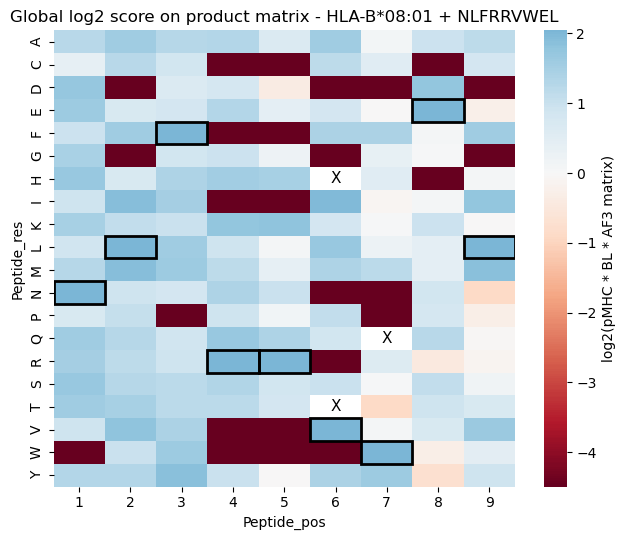

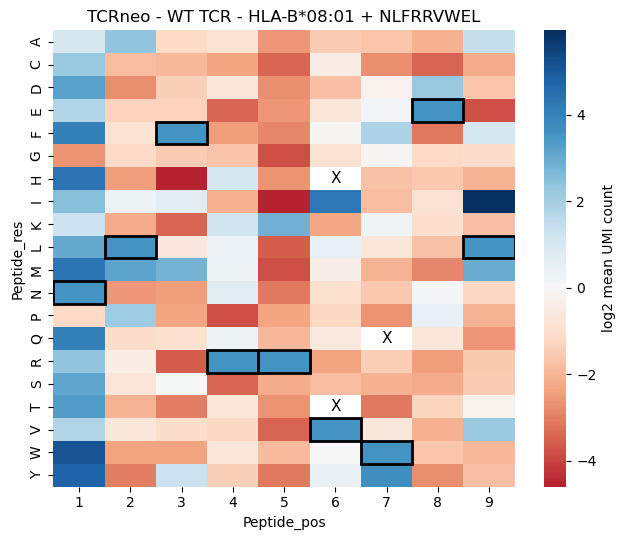

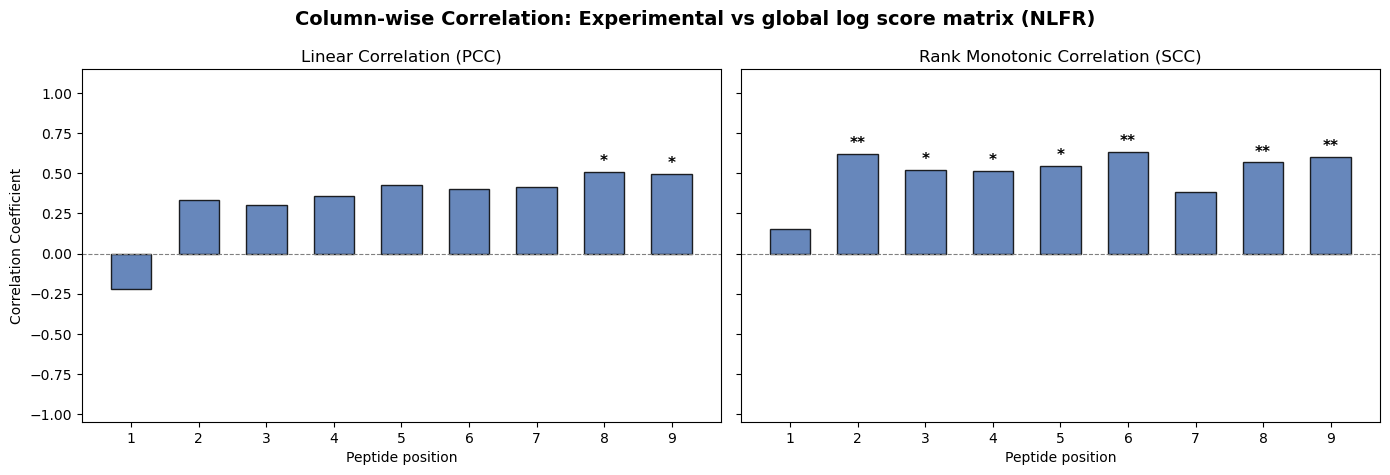

In [114]:
plot_heatmap(matrix_global_log, "log2(pMHC * BL * AF3 matrix)", "Global log2 score on product matrix", 0.0, "heatmap_log_glob_score", save_fig = True)
plot_heatmap(matrix_exp, "log2 mean UMI count", f"{exp_prefix} - WT TCR", 0.0) # as a reminder to compare
pcc_log_score_exp = compute_columnwise_pcc(matrix_exp, matrix_global_log)

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_log_score_exp,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_log_score_exp.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")


plot_bars(
    ax2,
    pcc_log_score_exp,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_log_score_exp.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig1.suptitle(f"Column-wise Correlation: Experimental vs global log score matrix ({pep_short})", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(fig_folder, "pcc_exp_log_glob_score"), dpi=300)
plt.show()